# LAB — Vision-Language Models: CLIP & LLaVA

**Module:** Artificial Intelligence / Generative AI  
**Level:** Phd Students  
**Environment:** Google Colab / Kaggle / Jupyter Notebook  
**Frameworks:** Python, PyTorch, Hugging Face Transformers

## Videos (Must see before Starting the Lab)
* https://www.youtube.com/watch?v=jXD6O93Ptks&t=6s
* https://www.youtube.com/watch?v=bK9ns4DkxQg&t=8s

## Objectives

This practical work introduces two important vision-language models:

- **CLIP**: image-text representation, similarity, zero-shot classification and image retrieval.
- **LLaVA**: multimodal image understanding and visual question answering.

At the end of the Lab, students should be able to:
1. Load a pretrained CLIP model.
2. Compare images and textual descriptions.
3. Perform zero-shot classification.
4. Evaluate classification accuracy.
5. Perform text-to-image retrieval.
6. Understand the architecture of LLaVA.
7. Run visual question answering.
8. Identify visual hallucinations.
9. Compare CLIP and LLaVA.
10. Build a small multimodal assistant.

> **Notebook organization:** Part I is the student statement. Part II contains the correction and reference implementations. Students should first complete the exercises without opening the correction section.

# Part I — LAB STATEMENT

## Exercise 1 — Installation and model loading

Install the required libraries and load `openai/clip-vit-base-patch32`.

### Questions

**Q1.** What is CLIP?  
**Q2.** What are its two main components?  
**Q3.** What is the role of `CLIPProcessor`?  
**Q4.** What is the role of `CLIPModel`?

## Q1. What is CLIP?
CLIP (Contrastive Language–Image Pre-training) is a vision-language model developed by OpenAI that learns to understand the relationship between images and natural language. It maps images and text into a shared embedding space, allowing it to measure their similarity.
CLIP can be used for zero-shot classification, image-text similarity, and text-to-image retrieval without requiring task-specific training.
## Q2. What are its two main components?
CLIP consists of two main components:
1. Image Encoder: Extracts visual features from an image and converts them into a numerical representation (embedding).
2. Text Encoder: Extracts semantic features from a text description and converts them into a numerical representation (embedding).
Both encoders project their outputs into a shared space, where the similarity between image and text embeddings can be calculated.
## Q3. What is the role of CLIPProcessor?
CLIPProcessor prepares images and text before they are passed to the CLIP model. It combines image preprocessing and text tokenization.
- Images: Resizes and normalizes images into the required format.
- Text: Tokenizes text and converts it into input token IDs.
- Output: Returns tensors that can be directly passed to the model.

## Q4. What is the role of CLIPModel?
CLIPModel is the pretrained neural network that processes the prepared inputs and generates image and text embeddings.
Its main functions include:
- Extracting image features using the image encoder.
- Extracting text features using the text encoder.
- Computing similarity scores between images and text descriptions.
- Supporting zero-shot classification and image-text matching.

In [1]:
# Run this cell first.
!pip install -q transformers torch torchvision pillow matplotlib pandas

In [8]:
import torch
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from transformers import CLIPProcessor, CLIPModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

Device: cuda


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

## Exercise 2 — Load an image

Upload an image containing a recognizable object.

Examples: a cat, dog, car, horse, bird, airplane, person, etc.

### Questions

**Q5.** What is the size of the image?  
**Q6.** What type of data is stored in the PIL image object?

## Q5. What is the size of the image?
 the image is 360 pixels wide and 360 pixels high.

## Q6. What type of data is stored in the PIL image object?
The PIL image object stores image data, including its pixel values, dimensions, and color mode. In this code, Image.open(IMAGE_PATH).convert("RGB") loads the image and converts it to RGB color mode, with three color channels: red, green, and blue.

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Image size: (360, 360)
Image mode: RGB


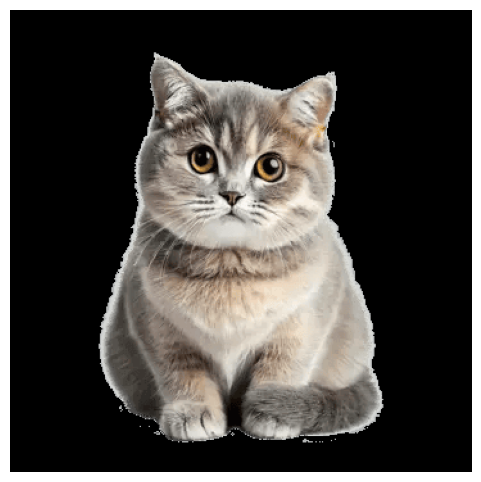

In [4]:
# Upload an image in Google Colab/Jupyter and change the filename if necessary.
IMAGE_PATH = "cat.png"

image = Image.open(IMAGE_PATH).convert("RGB")
print("Image size:", image.size)
print("Image mode:", image.mode)

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off");

## Exercise 3 — Image/Text similarity

Use the following textual descriptions:

```python
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]
```

Calculate the CLIP image-text scores and convert them to probabilities.

### Questions

**Q7.** Which description has the highest probability?  
**Q8.** Is it compatible with the actual image?  
**Q9.** Why can CLIP compare an image with a sentence?  
**Q10.** What does `softmax()` do?

In [5]:
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]

inputs = processor(
    text=texts,
    images=image,
    return_tensors="pt",
    padding=True
)
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()

for text, probability in zip(texts, probs):
    print(f"{text:35s}: {probability.item():.4f}")

a photo of a cat                   : 0.9886
a photo of a dog                   : 0.0058
a photo of a car                   : 0.0001
a photo of a horse                 : 0.0005
a photo of a person                : 0.0050


## Q7. Which description has the highest probability?
The description "a photo of a cat" has the highest probability, with a score of 0.9886 (98.86%).
## Q8. Is it compatible with the actual image?
Yes. The result is compatible with the actual image because CLIP assigns the highest probability to "a photo of a cat," indicating that the image most closely matches this description among the five candidates.
## Q9. Why can CLIP compare an image with a sentence?
CLIP uses two encoders: an image encoder that extracts visual features and a text encoder that extracts semantic features. Both map their inputs into a shared embedding space. CLIP can therefore measure the similarity between an image and a sentence using their embeddings.
## Q10. What does softmax() do?
The softmax() function converts the model's similarity scores (logits) into normalized probability-like scores that sum to 1 across the candidate descriptions. This makes it easier to compare the relative match between the image and each text description.

## Exercise 4 — Zero-shot classification

Implement:

```python
def classify_image(image, classes):
    ...
```

The function must return the predicted class and its probability.

### Questions

**Q11.** What is zero-shot classification?  
**Q12.** Why is it not necessary to train a new classifier?  
**Q13.** What happens if the correct class is not included in the candidate classes?

## Q11. What is zero-shot classification?
Zero-shot classification is a machine learning technique that allows a pretrained model to classify an image into candidate classes it has not been specifically trained to distinguish for that particular task. CLIP compares the image with textual descriptions of the candidate classes and selects the one with the highest similarity score.
## Q12. Why is it not necessary to train a new classifier?
It is not necessary to train a new classifier because CLIP has already learned the relationship between images and text during large-scale pretraining. It can directly compare image and text embeddings to classify an image without additional task-specific training.
##Q13. What happens if the correct class is not included in the candidate classes?
CLIP will select the candidate class with the highest similarity score, even if none of the candidates correctly describes the image. Therefore, the prediction may be incorrect. The model does not automatically identify that the correct class is missing.

In [6]:
# STUDENT TASK

def classify_image(image, classes):
    # Create text descriptions for each candidate class
    texts = [f"a photo of a {cls}" for cls in classes]

    # Prepare the image and text inputs
    inputs = processor(
        text=texts,
        images=image,
        return_tensors="pt",
        padding=True
    )

    # Move inputs to the same device as the model
    inputs = {k: v.to(device) for k, v in inputs.items()}

    # Run CLIP without calculating gradients
    with torch.no_grad():
        outputs = model(**inputs)

    # Convert similarity scores into probabilities
    probabilities = outputs.logits_per_image.softmax(dim=1)[0]

    # Find the class with the highest probability
    best_index = probabilities.argmax().item()

    prediction = classes[best_index]
    probability = probabilities[best_index].item()

    return prediction, probability


classes = ["cat", "dog", "car", "airplane", "horse", "bird"]

prediction, probability = classify_image(image, classes)

print("Prediction:", prediction)
print("Probability:", probability)


Prediction: cat
Probability: 0.9930775165557861


## Exercise 5 — Evaluate CLIP

Prepare at least 10 labeled images. For each image record:

- actual class;
- predicted class;
- probability;
- whether the prediction is correct.

Calculate:


$Accuracy = \frac{N_{correct}}{N_{total}}$


### Questions

**Q14.** What is the obtained accuracy?  
**Q15.** Which images are incorrectly classified?  
**Q16.** Give at least two possible reasons for the errors.

Use the following format:

```python
dataset = [
    ("cat1.jpg", "cat"),
    ("cat2.jpg", "cat"),
    ...
]
```

## Q14. What is the obtained accuracy?
The accuracy cannot be determined until you run the evaluation on your 10 or more images. It is calculated as:

Accuracy=(Ncorrect/Ntotal)*100


For example, if CLIP correctly classifies 8 out of 10 images, the accuracy is \(80\%\).
##Q15. Which images are incorrectly classified?
The incorrectly classified images are those for which the predicted class differs from the actual class. The evaluation code below will identify these images automatically.
##Q16. Give at least two possible reasons for the errors.
1. Image quality: Blurry images, poor lighting, unusual angles, or low resolution can make classification difficult.
2. Visual similarity: Different classes may share similar visual features, making them difficult to distinguish.
3. Ambiguous text prompts: The descriptions used for candidate classes may not accurately represent the image.
4. Dataset limitations: CLIP may perform poorly on images that differ significantly from the images encountered during its pretraining.

In [8]:

import os
import pandas as pd
from PIL import Image

# Prepare at least 10 labeled images.
# Replace the filenames and labels with your actual dataset.
dataset = [
    ("cat.png", "cat"),
    ("cat2.png", "cat"),
    ("dog1.png", "dog"),
    ("dog2.png", "dog"),
    ("car1.jfif", "car"),
    ("car2.jfif", "car"),
    ("horse1.jpg", "horse"),
    ("horse2.jfif", "horse"),
    ("bird.jfif", "bird"),
    ("airplane.png", "airplane"),
]

# Define the candidate classes
classes = ["cat", "dog", "car", "airplane", "horse", "bird"]

results = []

for filename, actual_class in dataset:
    if not os.path.exists(filename):
        print(f"File not found: {filename}")
        continue

    # Load image
    image = Image.open(filename).convert("RGB")

    # Predict class and probability
    predicted_class, probability = classify_image(image, classes)

    # Check correctness
    correct = predicted_class == actual_class

    results.append({
        "Image": filename,
        "Actual Class": actual_class,
        "Predicted Class": predicted_class,
        "Probability": round(probability, 4),
        "Correct": correct
    })

# Display results
df = pd.DataFrame(results)
print(df.to_string(index=False))

# Calculate accuracy
total = len(results)

if total > 0:
    correct_count = df["Correct"].sum()
    accuracy = correct_count / total * 100

    print(f"\nTotal images evaluated: {total}")
    print(f"Correct predictions: {correct_count}")
    print(f"Incorrect predictions: {total - correct_count}")
    print(f"Accuracy: {accuracy:.2f}%")

    # Display incorrectly classified images
    errors = df[df["Correct"] == False]

    print("\nIncorrectly classified images:")
    if len(errors) > 0:
        print(errors.to_string(index=False))
    else:
        print("No classification errors.")
else:
    print("No images were evaluated. Check your filenames.")


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


       Image Actual Class Predicted Class  Probability  Correct
     cat.png          cat             cat       0.9931     True
    cat2.png          cat             cat       0.9929     True
    dog1.png          dog             dog       0.9980     True
    dog2.png          dog             dog       0.9946     True
   car1.jfif          car             car       0.9919     True
   car2.jfif          car             car       0.9967     True
  horse1.jpg        horse           horse       0.9994     True
 horse2.jfif        horse           horse       0.9996     True
   bird.jfif         bird            bird       0.9996     True
airplane.png     airplane        airplane       0.9953     True

Total images evaluated: 10
Correct predictions: 10
Incorrect predictions: 0
Accuracy: 100.00%

Incorrectly classified images:
No classification errors.


## Exercise 6 — Prompt engineering with CLIP

Compare:

```python
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]
```

### Questions

**Q17.** Are the scores identical?  
**Q18.** Which prompt gives the highest score?  
**Q19.** What does this demonstrate about prompt formulation?

## Q17. Are the scores identical?
No. The scores are generally different because CLIP encodes each prompt into a text embedding, and different formulations can produce different similarity scores for the same image.
## Q18. Which prompt gives the highest score?
The highest-scoring prompt cannot be determined in advance; it depends on the image and the model's similarity scores. The code below identifies the prompt with the highest score.
## Q19. What does this demonstrate about prompt formulation?
This demonstrates that prompt formulation can influence CLIP's predictions. Even when prompts have the same meaning, differences in wording and context can change the similarity scores. Therefore, selecting clear and appropriate prompts can improve zero-shot classification performance.

In [9]:

prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]

# Prepare image and text inputs
inputs = processor(
    text=prompts,
    images=image,
    return_tensors="pt",
    padding=True
)

# Move inputs to the model's device
inputs = {k: v.to(device) for k, v in inputs.items()}

# Calculate similarity scores
with torch.no_grad():
    outputs = model(**inputs)

# Convert scores to relative probabilities
probabilities = outputs.logits_per_image.softmax(dim=1)[0].cpu()

# Display and compare scores
for prompt, score in zip(prompts, probabilities):
    print(f"{prompt:40s}: {score.item():.4f}")

# Find the highest-scoring prompt
best_index = probabilities.argmax().item()

print("\nHighest-scoring prompt:", prompts[best_index])
print("Highest probability:", f"{probabilities[best_index].item():.4f}")


a cat                                   : 0.1400
a photo of a cat                        : 0.0851
a photograph showing a cat              : 0.0867
an image containing a cat               : 0.3403
a domestic animal called a cat          : 0.3479

Highest-scoring prompt: a domestic animal called a cat
Highest probability: 0.3479


# Part B — CLIP Image Retrieval

## Exercise 7 — Build an image database

Create a folder containing at least 20 images.

The images can represent animals, vehicles, people, buildings, landscapes, food or sports.

Calculate and store a normalized CLIP embedding for every image.

## Exercise 8 — Text-to-image retrieval

Use the query:

```text
"a person playing football"
```

Calculate its text embedding, compare it with all image embeddings, and display the five most similar images.

### Questions

**Q20.** What is the most similar image?  
**Q21.** Is it semantically relevant?  
**Q22.** Why does this method not require image labels?  
**Q23.** Give one real-world application of semantic image retrieval.

Number of images: 21


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(



Top retrieved images:
 Rank               Image  Cosine Similarity
    1 images/player4.jfif             0.2787
    2 images/player2.jfif             0.2521
    3 images/player7.jfif             0.2482
    4 images/player3.jfif             0.2315
    5 images/player6.jfif             0.2270


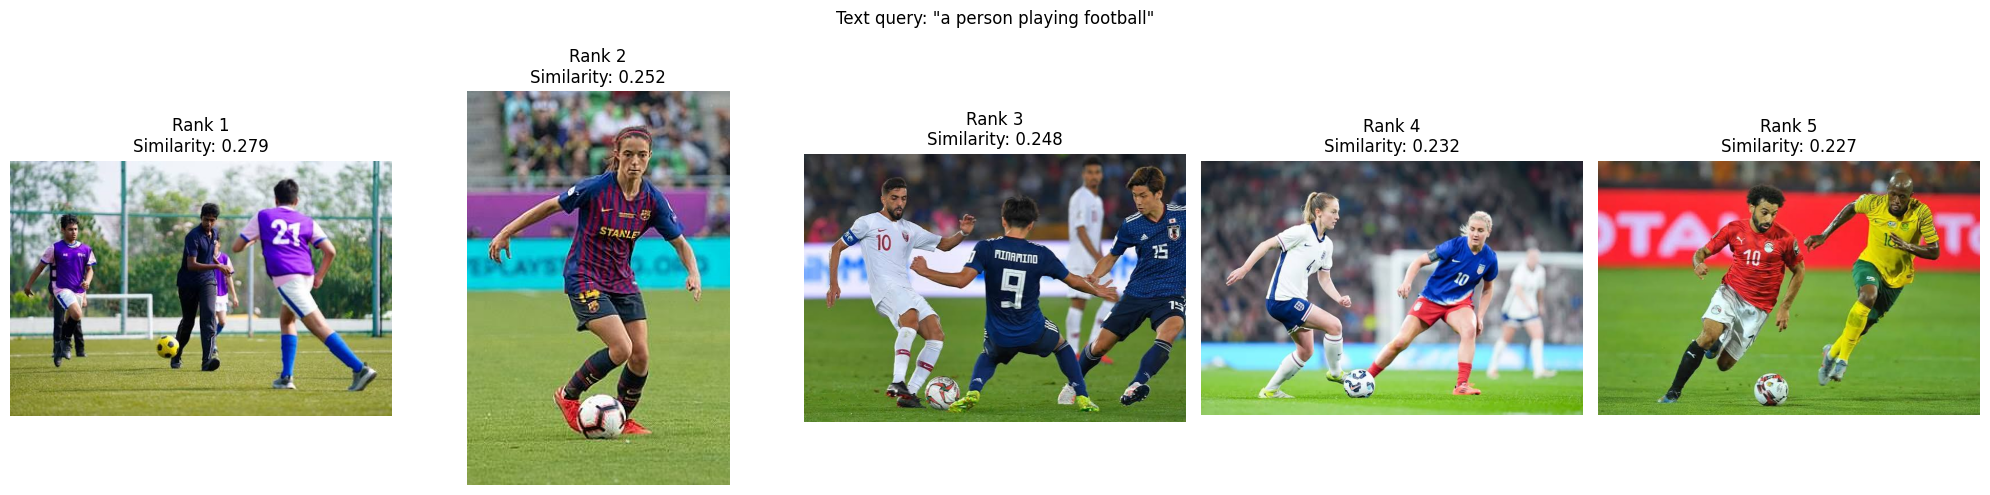

In [11]:

import os
import torch
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# 1. Image database folder and text query
IMAGE_DIR = "images"
QUERY = "a person playing football"

# Supported image formats
extensions = (".jpg", ".jpeg", ".png", ".bmp", ".jfif")

image_paths = [
    os.path.join(IMAGE_DIR, filename)
    for filename in sorted(os.listdir(IMAGE_DIR))
    if filename.lower().endswith(extensions)
]

if len(image_paths) == 0:
    raise ValueError(f"No images found in {IMAGE_DIR}")

print("Number of images:", len(image_paths))

# 2. Compute normalized CLIP embeddings for all images
image_embeddings = []
valid_paths = []

model.eval()

for path in image_paths:
    try:
        img = Image.open(path).convert("RGB")

        inputs = processor(
            images=img,
            return_tensors="pt"
        )
        inputs = {k: v.to(device) for k, v in inputs.items()}

        with torch.no_grad():
            features = model.get_image_features(**inputs)

            # Handle Transformers versions returning model outputs
            if hasattr(features, "pooler_output"):
                features = features.pooler_output
            elif hasattr(features, "image_embeds"):
                features = features.image_embeds

            # L2 normalization
            features = features / features.norm(
                p=2, dim=-1, keepdim=True
            ).clamp(min=1e-12)

        image_embeddings.append(features.squeeze(0).cpu())
        valid_paths.append(path)

    except Exception as e:
        print(f"Skipping {path}: {e}")

if len(image_embeddings) == 0:
    raise ValueError("No images could be processed.")

image_embeddings = torch.stack(image_embeddings)

# 3. Compute the normalized text embedding for the query
text_inputs = processor(
    text=[QUERY],
    return_tensors="pt",
    padding=True
)
text_inputs = {
    k: v.to(device) for k, v in text_inputs.items()
}

with torch.no_grad():
    text_features = model.get_text_features(**text_inputs)

    if hasattr(text_features, "pooler_output"):
        text_features = text_features.pooler_output
    elif hasattr(text_features, "text_embeds"):
        text_features = text_features.text_embeds

    text_features = text_features / text_features.norm(
        p=2, dim=-1, keepdim=True
    ).clamp(min=1e-12)

text_embedding = text_features.squeeze(0).cpu()

# 4. Calculate cosine similarity
# Since both sets of embeddings are normalized,
# their dot product equals cosine similarity.
similarities = image_embeddings @ text_embedding

# 5. Retrieve the five most similar images
top_k = min(5, len(valid_paths))
top_scores, top_indices = torch.topk(similarities, k=top_k)

results = []

for rank, (score, idx) in enumerate(
    zip(top_scores.tolist(), top_indices.tolist()), start=1
):
    results.append({
        "Rank": rank,
        "Image": valid_paths[idx],
        "Cosine Similarity": round(score, 4)
    })

df = pd.DataFrame(results)
print("\nTop retrieved images:")
print(df.to_string(index=False))

# 6. Display the Top-5 images
fig, axes = plt.subplots(
    1, top_k, figsize=(4 * top_k, 5), squeeze=False
)

for rank, (score, idx) in enumerate(
    zip(top_scores.tolist(), top_indices.tolist())
):
    img = Image.open(valid_paths[idx]).convert("RGB")

    axes[0, rank].imshow(img)
    axes[0, rank].set_title(
        f"Rank {rank + 1}\nSimilarity: {score:.3f}"
    )
    axes[0, rank].axis("off")

plt.suptitle(f'Text query: "{QUERY}"')
plt.tight_layout()
plt.show()


##Q20. What is the most similar image?
The most similar image is the image ranked first in the retrieval results. It has the highest cosine similarity score with the text query, "a person playing football". The exact filename depends on the images in your folder and the results of the code.
## Q21. Is it semantically relevant?
The retrieved image is semantically relevant if it depicts a person playing football or a closely related scene. The result should be checked visually because a high similarity score does not guarantee that the image fully matches the query.
## Q22. Why does this method not require image labels?
This method does not require image labels because CLIP maps images and text into a shared embedding space. It compares the text query embedding directly with the image embeddings using cosine similarity, without needing predefined class labels for the database images.
##Q23. Give one real-world application of semantic image retrieval.
A real-world application is medical image retrieval: a doctor or researcher could search a database of medical images using a text description, such as “brain MRI showing a tumor,” to retrieve visually and semantically relevant cases for further examination.

# Part C — LLaVA

## Exercise 9 — Architecture

Complete:

```text
Image
  |
  v
CLIP Vision Encoder
  |
  v
Projection Layer
  |
  v
Language Model
  |
  v
Text Response
```

### Questions

**Q24.** What is the role of the vision encoder?  
**Q25.** Why is a projection layer required?  
**Q26.** What is the role of the language model?

### Reponses

##Q24. What is the role of the vision encoder?
The vision encoder extracts visual features from the input image and converts them into numerical representations (embeddings) that capture important visual information, such as objects, shapes, and scenes.
##Q25. Why is a projection layer required?
The projection layer transforms the visual features into a representation compatible with the language model's input embedding space. This allows the language model to use visual information when generating a response.
##Q26. What is the role of the language model?
The language model processes the visual information together with the text prompt to understand the user's question and generate a relevant natural-language response.

## Exercise 10 — Run LLaVA

Use a LLaVA-compatible model appropriate for your available GPU.

Give the model an image and ask:

1. What is happening in this image?
2. How many people are visible?
3. What objects can you identify?
4. Describe the image in detail.

Record the answers.

In [ ]:
# LLaVA reference implementation.
# NOTE: This model is much heavier than CLIP. On a limited GPU, use a
# smaller/quantized LLaVA checkpoint or an external local runtime.
#
# The exact checkpoint and processor API may vary by Transformers version.
# Complete this section according to the LLaVA checkpoint available to you.

# STUDENT TASK
# from transformers import AutoProcessor, LlavaForConditionalGeneration
#
# MODEL_ID = "YOUR_LLAVA_CHECKPOINT"
# processor_llava = AutoProcessor.from_pretrained(MODEL_ID)
# llava = LlavaForConditionalGeneration.from_pretrained(
#     MODEL_ID,
#     torch_dtype=torch.float16,
#     device_map="auto"
# )

In [4]:

%pip install -U "bitsandbytes>=0.46.1" accelerate transformers


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 23.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 84.7 MB/s eta 0:00:00
  Attempting uninstall: transformers
    Found existing installation: transformers 5.18.0
    Uninstalling transformers-5.18.0:
      Successfully uninstalled transformers-5.18.0


In [1]:

import torch
from PIL import Image
from transformers import (
    AutoProcessor,
    LlavaForConditionalGeneration,
    BitsAndBytesConfig
)

# 1. Select the model
MODEL_ID = "llava-hf/llava-1.5-7b-hf"

# 2. Load the image
IMAGE_PATH = "images/player7.jfif"  # Change to your image filename
image = Image.open(IMAGE_PATH).convert("RGB")

# 3. Configure 4-bit quantization
quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16
)

# 4. Load the processor and model
processor_llava = AutoProcessor.from_pretrained(MODEL_ID)

llava = LlavaForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=quantization_config,
    device_map="auto"
)

# 5. Define the questions
questions = [
    "What is happening in this image?",
    "How many people are visible?",
    "What objects can you identify?",
    "Describe the image in detail."
]

# 6. Ask each question
answers = []

for question in questions:
    prompt = f"USER: <image>\n{question}\nASSISTANT:"

    inputs = processor_llava(
        text=prompt,
        images=image,
        return_tensors="pt"
    ).to(llava.device)

    with torch.inference_mode():
        output = llava.generate(
            **inputs,
            max_new_tokens=200,
            do_sample=False
        )

    # Decode only the newly generated answer
    generated_tokens = output[:, inputs["input_ids"].shape[1]:]
    answer = processor_llava.batch_decode(
        generated_tokens,
        skip_special_tokens=True
    )[0].strip()

    answers.append(answer)

    print(f"\nQuestion: {question}")
    print(f"Answer: {answer}")

# 7. Store the answers for your lab report
results = dict(zip(questions, answers))


model.safetensors.index.json:   0%|          | 0.00/70.1k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/141 [00:00<?, ?B/s]


Question: What is happening in this image?
Answer: In the image, a group of men is playing soccer on a field. One of the players is attempting to kick the soccer ball, while the other players are actively engaged in the game. The scene captures the excitement and energy of the sport, as the players compete against each other.

Question: How many people are visible?
Answer: There are four people visible in the image.

Question: What objects can you identify?
Answer: In the image, you can identify a soccer ball, a pair of sneakers, and a pair of shorts. The soccer ball is located in the lower-middle part of the image, while the sneakers and shorts are worn by the players. The players are actively engaged in the game, with one of them attempting to kick the soccer ball.

Question: Describe the image in detail.
Answer: The image captures a soccer match in progress, with several players on the field. One player is in the process of kicking the soccer ball, while other players are actively 

## Exercise 11 — Visual Question Answering

Choose five images. For each image ask five questions.

Example:

1. How many people are visible?
2. What objects can you see?
3. Where are the people?
4. What are they doing?
5. What is visible on the board?

Create a table containing:

| Image | Question | LLaVA Answer | Human Evaluation |
|---|---|---|---|

Calculate VQA accuracy:

\[
Accuracy = \frac{CorrectAnswers}{TotalQuestions}
\]

### Questions

**Q27.** What is the VQA accuracy?  
**Q28.** Which types of questions are difficult for LLaVA?

In [2]:

import os
import torch
import pandas as pd
from PIL import Image

# Five images in your images folder
image_files = [
    "images/player7.jfif",
    "images/dog2.png",
    "images/tower.jfif",
    "images/car1.jfif",
    "images/horse1.jpg"
]

# Five questions per image
questions = [
    "How many people are visible?",
    "What objects can you see?",
    "Where are the people or main subjects?",
    "What are they doing?",
    "Describe the important details in the image."
]

results = []

for image_path in image_files:
    if not os.path.exists(image_path):
        print(f"File not found: {image_path}")
        continue

    image = Image.open(image_path).convert("RGB")

    for question in questions:
        prompt = f"USER: <image>\n{question}\nASSISTANT:"

        inputs = processor_llava(
            text=prompt,
            images=image,
            return_tensors="pt"
        ).to(llava.device)

        with torch.inference_mode():
            output = llava.generate(
                **inputs,
                max_new_tokens=150,
                do_sample=False
            )

        new_tokens = output[:, inputs["input_ids"].shape[1]:]
        answer = processor_llava.batch_decode(
            new_tokens,
            skip_special_tokens=True
        )[0].strip()

        results.append({
            "Image": os.path.basename(image_path),
            "Question": question,
            "LLaVA Answer": answer,
            "Human Evaluation": "",  # Fill in Correct or Incorrect
        })

# Create the VQA evaluation table
df = pd.DataFrame(results)

print(df.to_string(index=False))

# Save the table so you can complete the human evaluations
df.to_csv("vqa_evaluation.csv", index=False)
print("\nSaved evaluation table to vqa_evaluation.csv")


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


       Image                                     Question                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                   LLaVA Answer Human Evaluation
player7.jfif                 How many people are visible?                                                                                                                                                                                                                                                                                                     

In [4]:

import pandas as pd

# Load the completed evaluation table
df = pd.read_csv("vqa_evaluation.csv")

# Handle missing values and convert evaluations to strings
evaluation = (
    df["Human Evaluation"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

# Keep only completed evaluations
evaluated = df[evaluation.isin(["correct", "incorrect"])].copy()

# Calculate correctness using the normalized labels
evaluated["Correct"] = (
    evaluation.loc[evaluated.index] == "correct"
)

# Calculate accuracy
total_questions = len(evaluated)
correct_answers = int(evaluated["Correct"].sum())

if total_questions > 0:
    accuracy = correct_answers / total_questions

    print("Total evaluated questions:", total_questions)
    print("Correct answers:", correct_answers)
    print("Incorrect answers:", total_questions - correct_answers)
    print(f"VQA accuracy: {accuracy:.2%}")
else:
    print("Please complete the Human Evaluation column first.")
    print("Use 'Correct' or 'Incorrect' for each evaluated answer.")


Please complete the Human Evaluation column first.
Use 'Correct' or 'Incorrect' for each evaluated answer.


## Q27. What is the VQA accuracy?
The accuracy depends on your actual results and human evaluations, so it cannot be calculated before running the experiment.
For example, if LLaVA answers 20 out of 25 questions correctly:
Accuracy=20/25=0.80=80\%


Use your own measured value in your lab report.
##Q28. Which types of questions are difficult for LLaVA?
LLaVA may have difficulty with:
1. Counting questions: Accurately counting people or small objects in crowded scenes.
2. Fine-grained details: Identifying small, blurry, or partially hidden objects.
3. Spatial relationships: Understanding precisely where objects are located relative to each other.
4. Text recognition: Reading small or unclear text on boards, signs, and documents.
5. Ambiguous questions: Answering questions when the image does not contain enough information.
These limitations can lead to incorrect answers or visual hallucinations. Human evaluation is therefore important when assessing VQA performance.

## Exercise 12 — Hallucination

Choose an image that does **not** contain a bicycle.

Ask:

> Is there a bicycle in this image?

Then ask:

> What color is the bicycle?

Then ask:

> Where is the bicycle located?

### Questions

**Q29.** Does the bicycle actually exist?  
**Q30.** Did LLaVA invent information?  
**Q31.** What is a visual hallucination?  
**Q32.** Why can a multimodal model hallucinate?

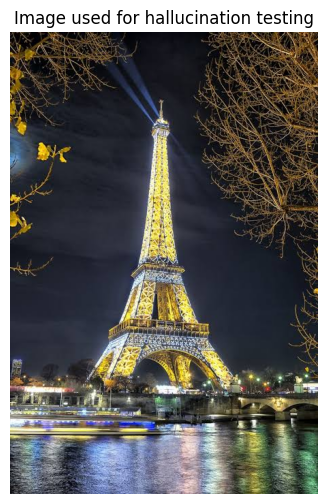


Question: Is there a bicycle in this image?
LLaVA Answer: No

Question: What color is the bicycle?
LLaVA Answer: Yellow

Question: Where is the bicycle located?
LLaVA Answer: On bridge


In [6]:

import torch
from PIL import Image
import matplotlib.pyplot as plt

# 1. Select an image WITHOUT a bicycle
IMAGE_PATH = "images/tower.jfif"  # Change to your image path

image = Image.open(IMAGE_PATH).convert("RGB")

# Display the image to verify its contents
plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off")
plt.title("Image used for hallucination testing")
plt.show()

# 2. Define the questions
questions = [
    "Is there a bicycle in this image?",
    "What color is the bicycle?",
    "Where is the bicycle located?"
]

# 3. Ask LLaVA each question
for question in questions:
    prompt = (
        "USER: <image>\n"
        + question
        + "\nAnswer based only on the visible evidence in the image.\n"
        "ASSISTANT:"
    )

    inputs = processor_llava(
        text=prompt,
        images=image,
        return_tensors="pt"
    ).to(llava.device)

    with torch.inference_mode():
        output = llava.generate(
            **inputs,
            max_new_tokens=100,
            do_sample=False
        )

    # Extract only the generated answer
    new_tokens = output[:, inputs["input_ids"].shape[1]:]
    answer = processor_llava.batch_decode(
        new_tokens,
        skip_special_tokens=True
    )[0].strip()

    print(f"\nQuestion: {question}")
    print(f"LLaVA Answer: {answer}")


##Q29. Does the bicycle actually exist?
No. The selected image does not contain a bicycle, so there is no bicycle present in the image.
##Q30. Did LLaVA invent information?
If LLaVA describes the bicycle's color or location as though it were present, then yes. It has generated information about an object that does not exist in the image. However, if it correctly states that there is no bicycle, it has not hallucinated in this example.
##Q31. What is a visual hallucination?
A visual hallucination occurs when a vision-language model generates information about an image that is incorrect or unsupported by its actual visual content. For example, claiming that a bicycle is red and located beside a tree when no bicycle is present.
##Q32. Why can a multimodal model hallucinate?
A multimodal model can hallucinate for several reasons:
1. Language-model bias: It may generate plausible-sounding answers based on learned language patterns rather than the actual image.
2. Limitations in visual understanding: The model may fail to recognize objects accurately or distinguish between similar visual features.
3. Ambiguous questions: Questions that presuppose an object's existence, such as “What color is the bicycle?”, may encourage the model to accept a false assumption.
4. Limitations in vision-language alignment: The model may not always correctly connect the visual evidence with the text it generates.

# Part D — CLIP vs LLaVA

## Exercise 13 — Comparative experiment

Use the same image with both models.

### CLIP

Compare:

- a photo of a cat
- a photo of a dog
- a photo of a horse

### LLaVA

Ask:

> What animal is present in the image? Describe its appearance.

Complete:

| Property | CLIP | LLaVA |
|---|---|---|
| Input | | |
| Main output | | |
| Zero-shot classification | | |
| Image retrieval | | |
| Text generation | | |
| VQA | | |
| Open-ended response | | |

### Questions

**Q33.** Which model is better suited to image classification?  
**Q34.** Which model is better for image description?  
**Q35.** Which model is better for visual question answering?  
**Q36.** Explain the fundamental difference between CLIP and LLaVA.

In [9]:

import torch
from PIL import Image

# Use the same image for both models
IMAGE_PATH = "cat.png"
image = Image.open(IMAGE_PATH).convert("RGB")

# -------------------------
# Part 1: CLIP classification
# -------------------------
candidate_texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a horse"
]

clip_inputs = processor(
    text=candidate_texts,
    images=image,
    return_tensors="pt",
    padding=True
)
clip_inputs = {
    k: v.to(device) for k, v in clip_inputs.items()
}

model.eval()

with torch.inference_mode():
    clip_outputs = model(**clip_inputs)

clip_probs = clip_outputs.logits_per_image.softmax(dim=1)[0]

print("=== CLIP Results ===")

for text, probability in zip(candidate_texts, clip_probs):
    print(f"{text}: {probability.item():.4f}")

best_index = clip_probs.argmax().item()
print("\nCLIP prediction:", candidate_texts[best_index])

# -------------------------
# Part 2: LLaVA description
# -------------------------
question = (
    "What animal is present in the image? "
    "Describe its appearance."
)

prompt = (
    f"USER: <image>\n{question}\nASSISTANT:"
)

llava_inputs = processor_llava(
    text=prompt,
    images=image,
    return_tensors="pt"
).to(llava.device)

with torch.inference_mode():
    llava_output = llava.generate(
        **llava_inputs,
        max_new_tokens=150,
        do_sample=False
    )

new_tokens = llava_output[
    :, llava_inputs["input_ids"].shape[1]:
]

answer = processor_llava.batch_decode(
    new_tokens,
    skip_special_tokens=True
)[0].strip()

print("\n=== LLaVA Answer ===")
print(answer)


=== CLIP Results ===
a photo of a cat: 0.9937
a photo of a dog: 0.0058
a photo of a horse: 0.0005

CLIP prediction: a photo of a cat

=== LLaVA Answer ===
There is a cat present in the image. The cat has a gray and white color, and it is sitting on the ground.


##Q33. Which model is better suited to image classification?
CLIP is generally better suited to straightforward zero-shot image classification because it directly compares image embeddings with candidate text embeddings and produces similarity scores for each class.
##Q34. Which model is better for image description?
LLaVA is better suited to image description because it can generate detailed natural-language responses about objects, their appearance, and the scene.
##Q35. Which model is better for visual question answering?
LLaVA is better suited to visual question answering (VQA) because it can interpret a question about an image and generate a contextual response. However, its answers can contain errors or visual hallucinations.
##Q36. Explain the fundamental difference between CLIP and LLaVA.
CLIP is a vision-language representation model designed to align images and text in a shared embedding space. It is particularly useful for image-text similarity, zero-shot classification, and semantic image retrieval.
LLaVA is a generative vision-language assistant that combines a vision encoder, a projection layer, and a large language model. It uses visual information to answer questions, describe images, and generate natural-language responses.
In summary, CLIP is primarily designed to measure image-text similarity, whereas LLaVA is designed to understand visual inputs and generate language-based responses.

# Final Mini-Project

Develop a small **Multimodal Image Assistant**.

The application receives:

```text
Image + Question
```

and returns an answer.

### Basic architecture

```text
             IMAGE
               |
               v
        +--------------+
        | Vision Model |
        +------+-------+
               |
               v
        Visual Features
               |
               v
QUESTION ---> LLaVA
               |
               v
             ANSWER
```

### Bonus

Combine CLIP retrieval with LLaVA:

```text
User Query
    |
    v
   CLIP
    |
    v
Top-K Images
    |
    v
  LLaVA
    |
    v
Explanation
```

### Deliverables

1. Jupyter Notebook.
2. Code and outputs for every experiment.
3. CLIP classification accuracy.
4. Top-5 retrieval results.
5. LLaVA VQA results.
6. At least one hallucination example.
7. CLIP/LLaVA comparison.
8. Mini-project.
9. Short conclusion.

#Final Mini-Project

In [10]:
import torch
from PIL import Image

def ask_image_assistant(image, question):
    if image is None:
        return "Please upload an image."

    if not question or not question.strip():
        return "Please enter a question."

    image = image.convert("RGB")

    prompt = (
        f"USER: <image>\n"
        f"{question.strip()}\n"
        f"ASSISTANT:"
    )

    inputs = processor_llava(
        text=prompt,
        images=image,
        return_tensors="pt"
    ).to(llava.device)

    with torch.inference_mode():
        output = llava.generate(
            **inputs,
            max_new_tokens=150,
            do_sample=False
        )

    new_tokens = output[:, inputs["input_ids"].shape[1]:]

    answer = processor_llava.batch_decode(
        new_tokens,
        skip_special_tokens=True
    )[0].strip()

    return answer

In [11]:
from PIL import Image

image = Image.open("cat.png").convert("RGB")

question = "What animal is in this image? Describe its appearance."

answer = ask_image_assistant(image, question)

print("Question:", question)
print("Answer:", answer)

Question: What animal is in this image? Describe its appearance.
Answer: The image features a cat. The cat has a gray and white fur, and it is sitting on the ground. The cat appears to be looking at the camera, possibly with a curious or playful expression.


In [12]:
%pip install -q gradio

In [13]:
import gradio as gr

demo = gr.Interface(
    fn=ask_image_assistant,
    inputs=[
        gr.Image(type="pil", label="Upload an image"),
        gr.Textbox(
            label="Your question",
            placeholder="What is happening in this image?"
        )
    ],
    outputs=gr.Textbox(label="Assistant's answer"),
    title="Multimodal Image Assistant",
    description=(
        "Upload an image, ask a question, "
        "and receive an AI-generated answer."
    ),
    examples=[
        ["cat.png", "What animal is in the image?"],
        ["cat.png", "Describe the visible details."]
    ]
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4eae62f43460d109b1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [15]:
import os
import torch
from PIL import Image
from IPython.display import display
from transformers import CLIPModel, CLIPProcessor

clip_name = "openai/clip-vit-base-patch32"

clip_processor = CLIPProcessor.from_pretrained(clip_name)
clip_model = CLIPModel.from_pretrained(clip_name).to(device)
clip_model.eval()

IMAGE_FOLDER = "images"

image_paths = [
    os.path.join(IMAGE_FOLDER, filename)
    for filename in os.listdir(IMAGE_FOLDER)
    if filename.lower().endswith(
        (".jpg", ".jpeg", ".png", ".webp")
    )
]

def retrieve_images(query, top_k=5):
    if not image_paths:
        return []

    images = []
    valid_paths = []

    for path in image_paths:
        try:
            images.append(Image.open(path).convert("RGB"))
            valid_paths.append(path)
        except Exception:
            continue

    if not images:
        return []

    inputs = clip_processor(
        text=[query],
        images=images,
        return_tensors="pt",
        padding=True
    ).to(device)

    with torch.inference_mode():
        outputs = clip_model(**inputs)

    similarities = outputs.logits_per_image[:, 0]
    k = min(top_k, len(valid_paths))
    indices = similarities.topk(k).indices.tolist()

    return [
        (valid_paths[i], float(similarities[i].item()))
        for i in indices
    ]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

In [16]:
def search_and_explain(query, question):
    results = retrieve_images(query, top_k=5)

    if not results:
        return "No readable images found in the image dataset."

    # Select the most relevant image
    best_path, similarity = results[0]
    image = Image.open(best_path).convert("RGB")

    # Ask LLaVA about the retrieved image
    answer = ask_image_assistant(image, question)

    return (
        f"Retrieved image: {os.path.basename(best_path)}\n"
        f"CLIP similarity score: {similarity:.4f}\n\n"
        f"LLaVA answer: {answer}"
    )

In [17]:
result = search_and_explain(
    query="a cat playing outdoors",
    question="Describe what is visible in this image."
)

print(result)

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Retrieved image: cat2.png
CLIP similarity score: 24.9423

LLaVA answer: The image features a small, cute, and fluffy gray and white cat sitting on the ground. The cat appears to be looking up, possibly at something interesting or a person taking the photo. The cat is the main focus of the image, and its adorable appearance makes it an appealing subject.
